# The AI pay penalty that isn't
### Do developers who use AI daily earn less? Untangling AI adoption, country and experience in the 2025 Stack Overflow survey

In the raw 2025 Stack Overflow survey data, developers who use AI tools **daily** report **lower** pay than
developers who don't use AI at all. A quick chart would conclude that AI use goes with lower pay.

This notebook shows that the raw gap comes from **who** uses AI daily, and then estimates
the gap between comparable developers:

1. **Raw comparison:** daily AI users earn less.
2. **Composition:** where daily users live and how experienced they are.
3. **Within-country view:** each developer's pay percentile *inside their own country*.
4. **Regression ladder:** how the AI coefficient changes as controls are added, with 95% confidence intervals.
5. **Prediction check:** does knowing someone's AI use help a gradient-boosted model predict their pay?
6. **India section:** the same questions for Indian developers, including students looking at their first job.

> **This is association, not causation.** People choose whether to use AI. The goal is to remove the most obvious
> confounders and see what is left, not to claim that AI raises anyone's salary.

*Data: [Stack Overflow Developer Survey 2025](https://survey.stackoverflow.co/2025), released under the Open Database License (ODbL 1.0).*

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import lightgbm as lgb
from sklearn.model_selection import KFold

SEED = 2025
rng = np.random.default_rng(SEED)

# Works on Kaggle (/kaggle/input/...) and locally (./data)
candidates = list(Path("/kaggle/input").glob("**/survey_results_public.csv")) + [Path("data/survey_results_public.csv")]
DATA = next(p for p in candidates if p.exists())
raw = pd.read_csv(DATA, low_memory=False, encoding="utf-8", encoding_errors="replace")
print(f"{raw.shape[0]:,} respondents x {raw.shape[1]} columns")

49,191 respondents x 172 columns


In [2]:
# Chart style: validated categorical palette, thin marks, recessive grid, ink-colored text.
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "figure.dpi": 110,
})
AI_ORDER = ["none", "rarely", "weekly", "daily"]
AI_LABEL = {"none": "Don't use AI", "rarely": "Monthly or less", "weekly": "Weekly", "daily": "Daily"}

## 1. Cleaning, with a reason for each filter

| Filter | Why |
|---|---|
| Professional developers, employed full-time | Students, freelancers and part-timers report pay on very different bases |
| `ConvertedCompYearly` present | The survey's own conversion to USD/year |
| Drop the top and bottom 2% **within each country** | Removes typos (e.g. $1 or $50M) without letting rich countries set the cutoff for poor ones |
| Countries with ≥ 50 remaining respondents | So that within-country comparisons have enough data |
| AI-use answer present | It's the variable we're studying; "planning to" and "don't plan to" are both coded as non-users |

In [3]:
AI_MAP = {
    "Yes, I use AI tools daily": "daily",
    "Yes, I use AI tools weekly": "weekly",
    "Yes, I use AI tools monthly or infrequently": "rarely",
    "No, but I plan to soon": "none",
    "No, and I don't plan to": "none",
}

d = raw[(raw.MainBranch == "I am a developer by profession")
        & (raw.Employment == "Employed")
        & raw.ConvertedCompYearly.notna()
        & raw.WorkExp.notna()].copy()
steps = [("professional, employed, with pay + experience", len(d))]

q = d.groupby("Country").ConvertedCompYearly
d = d[d.ConvertedCompYearly.between(q.transform(lambda s: s.quantile(.02)), q.transform(lambda s: s.quantile(.98)))]
steps.append(("after per-country 2% trim", len(d)))

counts = d.Country.value_counts()
d = d[d.Country.isin(counts[counts >= 50].index)]
steps.append(("countries with >= 50 respondents", len(d)))

d["ai"] = d.AISelect.map(AI_MAP)
d = d[d.ai.notna()].copy()
steps.append(("with an AI-use answer", len(d)))

d["log_pay"] = np.log(d.ConvertedCompYearly)
d["exp"] = d.WorkExp.clip(upper=40)
d["country_pct"] = d.groupby("Country").ConvertedCompYearly.rank(pct=True) * 100
for col in ["OrgSize", "RemoteWork", "EdLevel", "ICorPM", "Age"]:
    d[col] = d[col].fillna("Not answered")

display(pd.DataFrame(steps, columns=["step", "rows"]))
print(f"{d.Country.nunique()} countries; AI-use mix:")
display(d.ai.value_counts(normalize=True).reindex(AI_ORDER).map("{:.1%}".format).rename(index=AI_LABEL).to_frame("share"))

,step,rows
0,"professional, employed, with pay + experience",16747
1,after per-country 2% trim,15932
2,countries with >= 50 respondents,14926
3,with an AI-use answer,14573


45 countries; AI-use mix:


,share
ai,
Don't use AI,18.8%
Monthly or less,13.3%
Weekly,18.4%
Daily,49.5%


## 2. The raw comparison: daily AI users earn less

,n,median_pay_usd,median_experience
ai,,,
Don't use AI,2738,"$87,230",12 yrs
Monthly or less,1934,"$84,460",11 yrs
Weekly,2685,"$81,262",11 yrs
Daily,7216,"$81,210",10 yrs


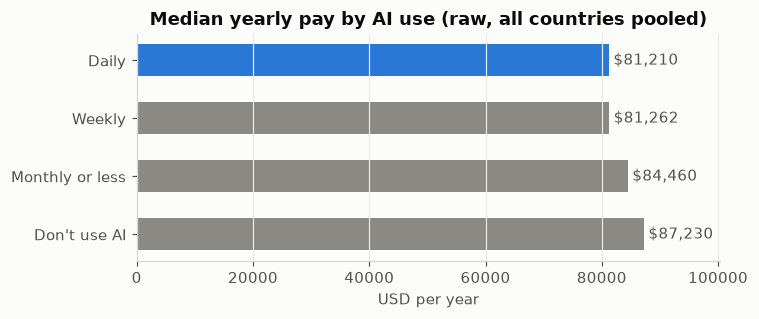

In [4]:
raw_tbl = (d.groupby("ai")
             .agg(n=("log_pay", "size"), median_pay_usd=("ConvertedCompYearly", "median"),
                  median_experience=("WorkExp", "median"))
             .reindex(AI_ORDER).rename(index=AI_LABEL))
display(raw_tbl.style.format({"median_pay_usd": "${:,.0f}", "median_experience": "{:.0f} yrs"}))

fig, ax = plt.subplots(figsize=(7, 3))
vals = raw_tbl.median_pay_usd
bars = ax.barh(vals.index, vals.values, color=[GRAY, GRAY, GRAY, BLUE], height=0.55)
for b, v in zip(bars, vals.values):
    ax.text(v + 800, b.get_y() + b.get_height() / 2, f"${v:,.0f}", va="center", color=INK2)
ax.set_title("Median yearly pay by AI use (raw, all countries pooled)")
ax.set_xlabel("USD per year"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, vals.max() * 1.15)
plt.tight_layout(); plt.show()

Taken at face value, daily users earn several thousand dollars a year less than non-users.
Before reading anything into that, it's worth checking whether the two groups are comparable. The next section looks at where each group lives.

## 3. Composition: where the daily users are

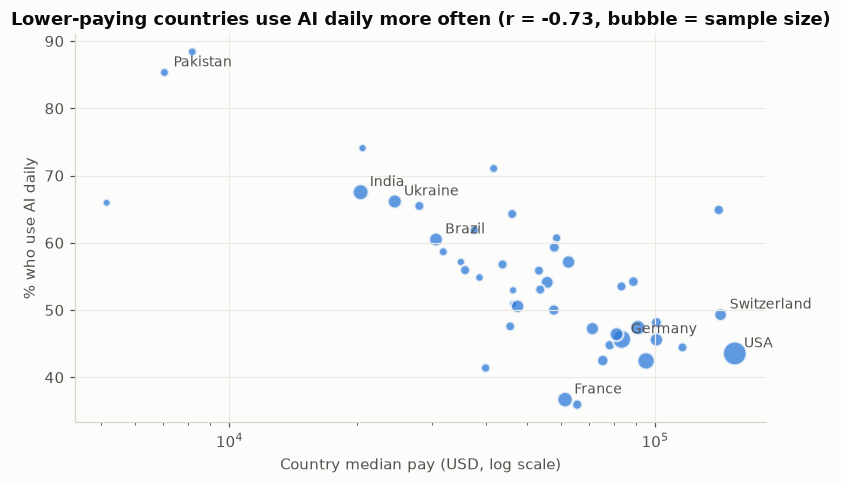

In [5]:
country_stats = (d.groupby("Country")
                   .agg(n=("ai", "size"), daily_share=("ai", lambda s: (s == "daily").mean()),
                        median_pay=("ConvertedCompYearly", "median")))
r = np.corrcoef(np.log(country_stats.median_pay), country_stats.daily_share)[0, 1]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(country_stats.median_pay, country_stats.daily_share * 100, s=np.sqrt(country_stats.n) * 4,
           color=BLUE, alpha=0.75, edgecolor="#fcfcfb", linewidth=1.5)
for name in ["India", "United States of America", "Germany", "Ukraine", "Brazil", "Switzerland", "Pakistan", "France"]:
    if name in country_stats.index:
        row = country_stats.loc[name]
        ax.annotate(name.replace("United States of America", "USA"), (row.median_pay, row.daily_share * 100),
                    xytext=(6, 4), textcoords="offset points", color=INK2, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Country median pay (USD, log scale)"); ax.set_ylabel("% who use AI daily")
ax.set_title(f"Lower-paying countries use AI daily more often (r = {r:.2f}, bubble = sample size)")
plt.tight_layout(); plt.show()

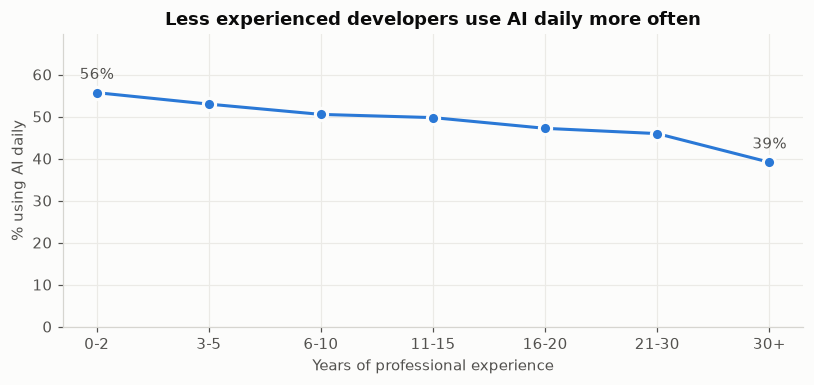

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = [0, 2, 5, 10, 15, 20, 30, 41]
labels = ["0-2", "3-5", "6-10", "11-15", "16-20", "21-30", "30+"]
d["exp_bin"] = pd.cut(d.exp, bins=bins, labels=labels, include_lowest=True)
share = d.groupby("exp_bin", observed=True).ai.apply(lambda s: (s == "daily").mean() * 100)
ax.plot(share.index.astype(str), share.values, color=BLUE, lw=2, marker="o", ms=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2)
for x, y in zip(share.index.astype(str)[[0, -1]], share.values[[0, -1]]):
    ax.annotate(f"{y:.0f}%", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", color=INK2)
ax.set_ylim(0, share.max() * 1.25)
ax.set_xlabel("Years of professional experience"); ax.set_ylabel("% using AI daily")
ax.set_title("Less experienced developers use AI daily more often")
plt.tight_layout(); plt.show()

Both of the strongest drivers of pay, **country** and **experience**, are tilted the same way:
daily AI use is more common in lower-paying countries and among junior developers. Pooling everyone
therefore compares a junior developer in one country with a senior developer in another.
The overall gap points the opposite way from the gaps inside each group (the same pattern as **Simpson's paradox**).

## 4. A fairer view: pay percentile *within* each country

Each developer gets their pay rank among respondents **in the same country** (0 = lowest, 100 = highest).
Country differences drop out entirely, and the average percentile of any group with no pay difference would be 50.

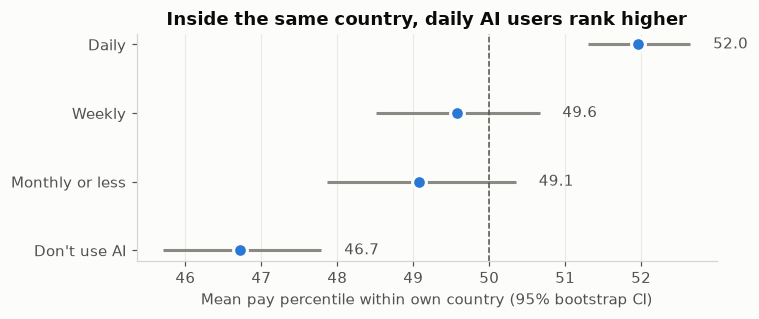

In [7]:
def boot_ci(x, n=2000):
    x = np.asarray(x)
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

pct_tbl = pd.DataFrame({
    a: {"mean_pct": g.mean(), "lo": boot_ci(g)[0], "hi": boot_ci(g)[1], "n": len(g)}
    for a, g in d.groupby("ai").country_pct
}).T.reindex(AI_ORDER)

fig, ax = plt.subplots(figsize=(7, 3))
y = np.arange(len(pct_tbl))
ax.hlines(y, pct_tbl.lo, pct_tbl.hi, color=GRAY, lw=2)
ax.plot(pct_tbl.mean_pct, y, "o", color=BLUE, ms=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
for yi, (m, hi) in enumerate(zip(pct_tbl.mean_pct, pct_tbl.hi)):
    ax.text(hi + 0.3, yi, f"{m:.1f}", va="center", color=INK2)
ax.axvline(50, color=INK2, lw=1, ls="--")
ax.set_yticks(y, [AI_LABEL[a] for a in pct_tbl.index])
ax.set_xlabel("Mean pay percentile within own country (95% bootstrap CI)")
ax.set_title("Inside the same country, daily AI users rank higher")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Once each developer is compared only with others in their own country, the sign flips: **daily users sit above
the median, and non-users sit below it.** That doesn't yet account for experience, company size or role.

## 5. Regression ladder: adding controls one at a time

The outcome is `log(pay)`, so a coefficient *b* means roughly **(e^b − 1) × 100 % higher pay** than non-users.
Standard errors are heteroskedasticity-robust (HC1).

In [8]:
SPECS = {
    "1. Raw": "log_pay ~ C(ai, Treatment('none'))",
    "2. + Country": "log_pay ~ C(ai, Treatment('none')) + C(Country)",
    "3. + Experience": "log_pay ~ C(ai, Treatment('none')) + C(Country) + exp + I(exp**2)",
    "4. + Company, remote, education, role": (
        "log_pay ~ C(ai, Treatment('none')) + C(Country) + exp + I(exp**2)"
        " + C(OrgSize) + C(RemoteWork) + C(EdLevel) + C(ICorPM)"),
}
rows, fits = [], {}
for name, f in SPECS.items():
    m = smf.ols(f, d).fit(cov_type="HC1")
    fits[name] = m
    for a in ["rarely", "weekly", "daily"]:
        k = f"C(ai, Treatment('none'))[T.{a}]"
        b, se = m.params[k], m.bse[k]
        rows.append({"model": name, "ai": a, "pct": (np.exp(b) - 1) * 100,
                     "lo": (np.exp(b - 1.96 * se) - 1) * 100, "hi": (np.exp(b + 1.96 * se) - 1) * 100,
                     "R2": m.rsquared})
ladder = pd.DataFrame(rows)
display(ladder[ladder.ai == "daily"].set_index("model")[["pct", "lo", "hi", "R2"]]
        .rename(columns={"pct": "daily vs none, %", "lo": "95% CI low", "hi": "95% CI high"})
        .style.format("{:+.1f}", subset=["daily vs none, %", "95% CI low", "95% CI high"]).format("{:.3f}", subset=["R2"]))

,"daily vs none, %",95% CI low,95% CI high,R2
model,,,,
1. Raw,-22.0,-25.1,-18.8,0.010
2. + Country,+6.1,+3.2,+9.0,0.531
3. + Experience,+7.4,+4.6,+10.2,0.578
"4. + Company, remote, education, role",+6.8,+4.1,+9.5,0.601


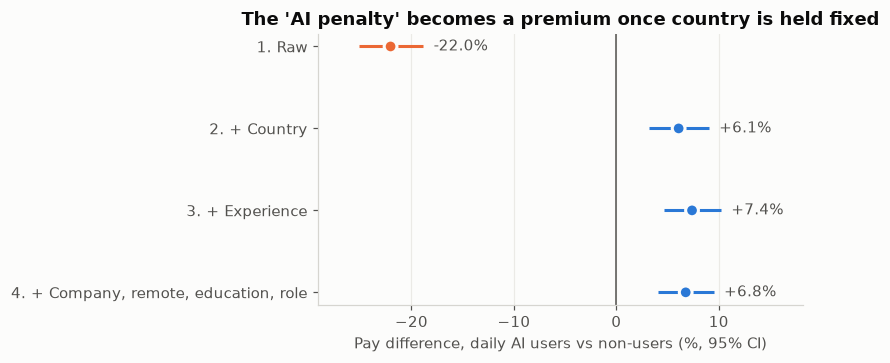

In [9]:
daily = ladder[ladder.ai == "daily"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(daily))[::-1]
colors = [ORANGE if v < 0 else BLUE for v in daily.pct]
ax.hlines(y, daily.lo, daily.hi, color=colors, lw=2)
ax.scatter(daily.pct, y, color=colors, s=70, zorder=3, edgecolor="#fcfcfb", linewidth=2)
for yi, v, hi in zip(y, daily.pct, daily.hi):
    ax.text(hi + 1, yi, f"{v:+.1f}%", va="center", color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, daily.model)
ax.set_xlabel("Pay difference, daily AI users vs non-users (%, 95% CI)")
ax.set_title("The 'AI penalty' becomes a premium once country is held fixed")
ax.grid(axis="y", visible=False)
ax.set_xlim(daily.lo.min() - 4, daily.hi.max() + 8)
plt.tight_layout(); plt.show()

The estimate changes sign at step 2, as soon as country is held fixed, and then stays stable:
experience, company size, remote status, education and IC-vs-manager shift it only slightly.
Among comparable developers, daily AI users report **a few percent higher** pay, and the confidence interval
excludes zero.

The size matters as much as the sign. Experience and country explain most of the variance (R² rises from ~0.01
to ~0.6), while the AI effect is a few percent. AI use is a minor factor in pay compared with those two.

## 6. Prediction check: does AI use help a model predict pay?

Regression coefficients answer *"holding other things fixed"*. Another useful question is how much information a variable adds.
I train LightGBM on `log(pay)` with 5-fold CV, **with and without** the AI columns, and compare out-of-fold error.
Small differences between the two are expected and still informative.

In [10]:
BASE = ["Country", "exp", "OrgSize", "RemoteWork", "EdLevel", "ICorPM", "Age", "DevType", "Industry"]
AI_COLS = ["AISelect", "AISent", "AIAgents", "AIThreat"]

X_all = d[BASE + AI_COLS].copy()
for c in X_all.columns:
    if not pd.api.types.is_numeric_dtype(X_all[c]):
        X_all[c] = X_all[c].fillna("NA").astype("category")
y_all = d.log_pay.values

def cv_rmse(cols, seeds=(0, 1, 2)):
    scores = []
    for s in seeds:
        oof = np.zeros(len(y_all))
        for tr, va in KFold(5, shuffle=True, random_state=s).split(X_all):
            model = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31,
                                      min_child_samples=40, subsample=0.8, subsample_freq=1,
                                      colsample_bytree=0.8, random_state=s, verbose=-1)
            model.fit(X_all.iloc[tr][cols], y_all[tr])
            oof[va] = model.predict(X_all.iloc[va][cols])
        scores.append(np.sqrt(np.mean((oof - y_all) ** 2)))
    return np.mean(scores), np.std(scores)

# Baseline: predict each country's median log pay (computed out-of-fold).
oof = np.zeros(len(y_all))
for tr, va in KFold(5, shuffle=True, random_state=0).split(X_all):
    med = d.iloc[tr].groupby("Country").log_pay.median()
    oof[va] = d.iloc[va].Country.map(med).fillna(np.median(y_all[tr])).values
baseline = np.sqrt(np.mean((oof - y_all) ** 2))

res = {"Country median only": (baseline, 0.0),
       "LightGBM without AI columns": cv_rmse(BASE),
       "LightGBM with AI columns": cv_rmse(BASE + AI_COLS)}
res_df = pd.DataFrame(res, index=["RMSE (log pay)", "sd over 3 seeds"]).T
res_df["typical miss (×)"] = np.exp(res_df["RMSE (log pay)"])
display(res_df.style.format({"RMSE (log pay)": "{:.4f}", "sd over 3 seeds": "{:.4f}", "typical miss (×)": "{:.2f}×"}))

,RMSE (log pay),sd over 3 seeds,typical miss (×)
Country median only,0.7207,0.0000,2.06×
LightGBM without AI columns,0.6373,0.0016,1.89×
LightGBM with AI columns,0.6341,0.0022,1.89×


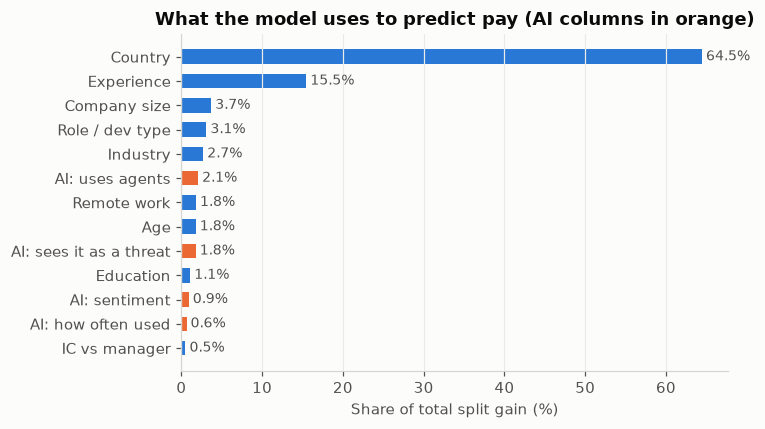

In [11]:
final = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
final.fit(X_all[BASE + AI_COLS], y_all)
imp = (pd.Series(final.booster_.feature_importance("gain"), index=BASE + AI_COLS)
         .sort_values() / final.booster_.feature_importance("gain").sum() * 100)
NICE = {"exp": "Experience", "OrgSize": "Company size", "DevType": "Role / dev type", "RemoteWork": "Remote work",
        "EdLevel": "Education", "ICorPM": "IC vs manager", "AIAgents": "AI: uses agents", "AIThreat": "AI: sees it as a threat",
        "AISent": "AI: sentiment", "AISelect": "AI: how often used"}

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([NICE.get(c, c) for c in imp.index], imp.values, color=[ORANGE if c in AI_COLS else BLUE for c in imp.index], height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("Share of total split gain (%)")
ax.set_title("What the model uses to predict pay (AI columns in orange)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Reading this:** a typical miss of 1.9× sounds large, but self-reported pay is noisy, and the model still clearly
beats the country-median baseline. Almost all of its accuracy comes from **country** and **experience**. Adding the four AI
columns lowers cross-validated error only slightly. Compare the gap with the across-seed spread in the table
before treating it as real. This agrees with the regression: the AI association is real but small
compared with where you work and how long you've worked.

## 7. India: what this means for students heading into their first job

India has the third-largest sample in the survey. All figures below are **within India only**.

India sample after cleaning: 739 employed professional developers


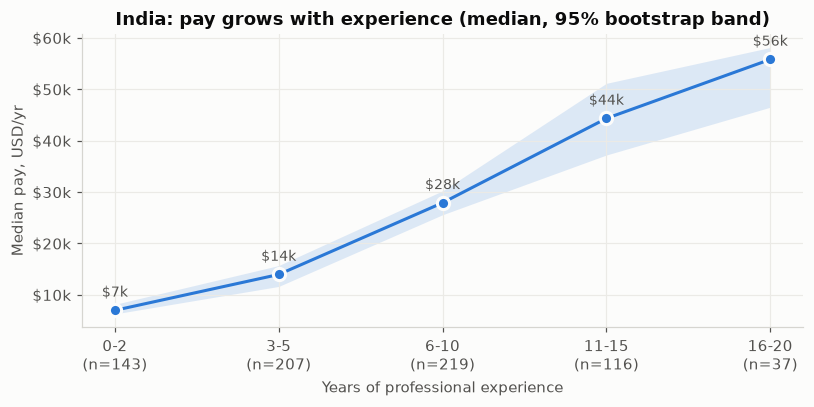

In [12]:
ind = d[d.Country == "India"].copy()
print(f"India sample after cleaning: {len(ind):,} employed professional developers")

def median_ci(x, n=2000):
    x = np.asarray(x)
    meds = np.median(rng.choice(x, size=(n, len(x)), replace=True), axis=1)
    return np.median(x), *np.percentile(meds, [2.5, 97.5])

curve = pd.DataFrame([(b, len(g), *median_ci(g.ConvertedCompYearly))
                      for b, g in ind.groupby("exp_bin", observed=True) if len(g) >= 20],
                     columns=["experience", "n", "median", "lo", "hi"])

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(curve))
ax.fill_between(x, curve.lo, curve.hi, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(x, curve["median"], color=BLUE, lw=2, marker="o", ms=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
for xi, m, n in zip(x, curve["median"], curve.n):
    ax.annotate(f"${m/1000:.0f}k", (xi, m), xytext=(0, 9), textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, [f"{e}\n(n={n})" for e, n in zip(curve.experience, curve.n)])
ax.set_xlabel("Years of professional experience"); ax.set_ylabel("Median pay, USD/yr")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.set_title("India: pay grows with experience (median, 95% bootstrap band)")
plt.tight_layout(); plt.show()

India, daily AI users vs non-users (controls: experience, company size, remote, role): +23.6%  (95% CI +6.4% to +43.6%)


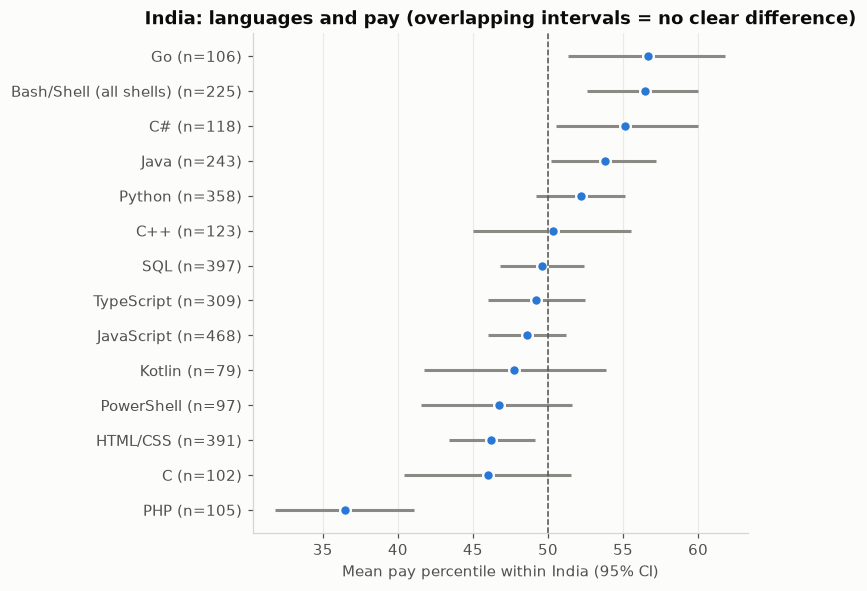

In [13]:
m_in = smf.ols("log_pay ~ C(ai, Treatment('none')) + exp + I(exp**2) + C(OrgSize) + C(RemoteWork) + C(ICorPM)",
               ind).fit(cov_type="HC1")
k = "C(ai, Treatment('none'))[T.daily]"
b, se = m_in.params[k], m_in.bse[k]
print(f"India, daily AI users vs non-users (controls: experience, company size, remote, role): "
      f"{(np.exp(b)-1)*100:+.1f}%  (95% CI {(np.exp(b-1.96*se)-1)*100:+.1f}% to {(np.exp(b+1.96*se)-1)*100:+.1f}%)")

# Which languages go with higher pay in India? Within-India percentile, languages with >= 60 users.
langs = ind.assign(lang=raw.loc[ind.index, "LanguageHaveWorkedWith"].str.split(";")).explode("lang").dropna(subset=["lang"])
lang_tbl = (langs.groupby("lang").agg(n=("country_pct", "size"), mean_pct=("country_pct", "mean"))
                 .query("n >= 60").sort_values("mean_pct"))
lang_tbl["lo"], lang_tbl["hi"] = zip(*[boot_ci(langs.loc[langs.lang == l, "country_pct"]) for l in lang_tbl.index])

fig, ax = plt.subplots(figsize=(7, 0.32 * len(lang_tbl) + 1))
y = np.arange(len(lang_tbl))
ax.hlines(y, lang_tbl.lo, lang_tbl.hi, color=GRAY, lw=2)
ax.plot(lang_tbl.mean_pct, y, "o", color=BLUE, ms=7, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.axvline(50, color=INK2, lw=1, ls="--")
ax.set_yticks(y, [f"{l} (n={n})" for l, n in zip(lang_tbl.index, lang_tbl.n)])
ax.set_xlabel("Mean pay percentile within India (95% CI)")
ax.set_title("India: languages and pay (overlapping intervals = no clear difference)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**India results:** the experience curve is steep. Median pay roughly doubles between 0–2 and 3–5 years, and again by 6–10 years.
With experience, company size, remote work and role controlled, Indian daily AI users report noticeably higher pay than
non-users. The interval is wide (n = 739), so treat the size of the gap as uncertain; the direction is the same as in the global model.
In the language chart, most intervals overlap the median. PHP is the one clear outlier on the low side.

## 8. Takeaways

1. **"AI users earn less" is a composition effect.** Daily AI use is concentrated in lower-paying countries and among
   junior developers. Pooling across countries reverses the sign.
2. **Among comparable developers, daily AI users report slightly higher pay**, a few percent, with confidence intervals
   that exclude zero. The estimate is stable once country is controlled.
3. **The effect is small.** Country and experience explain most of the explainable variance, and AI columns add little
   predictive power to a gradient-boosted model.
4. **For students:** the experience curve dominates everything else here. Time spent building real experience
   (internships, open-source contributions, shipped projects) matters far more than any single tool.

## Limitations

- **Self-selection.** Developers who adopt AI early may differ in ways the survey doesn't measure (curiosity, employer
  type, role). The premium could reflect those differences rather than AI itself.
- **Survey bias.** Respondents are Stack Overflow users who chose to answer, which is not a random sample of developers.
- **One year, cross-sectional data.** There is no before/after comparison for the same people.
- **Converted pay** depends on the exchange rates used, and ignores cost of living.

*Feedback is welcome. If you spot a modelling mistake, please leave a comment.*